
# Part 3 (continued) & Part 4 — Tuning, Threshold, SHAP Explainability and Fairness
### Hospital Readmission Prediction | Diabetes 130-US Hospitals (1999–2008)

Notebook 02 trained three models on a **patient-level split** and measured their
untuned performance. This notebook finishes the job:

1. Recover the exact same split (and the patient IDs it was built from).
2. **Cross-validation with `GroupKFold`** — folds grouped by patient.
3. **Hyperparameter tuning** of LightGBM (`RandomizedSearchCV`).
4. **Threshold choice** — trading false alarms against missed patients.
5. **SHAP** — which features drive each prediction.
6. **Fairness check** — does the model work equally well for every group?

> **Compute note (honest engineering):** a LightGBM fit costs ~2.5 minutes at full
> size on this machine, so the hyperparameter search runs on a stratified
> 12,000-row subsample with 3 sampled configurations and 3 patient-grouped folds.
> The winning configuration is then re-trained once on the full training set — the
> standard coarse-to-fine workflow under a real compute budget.


In [1]:
import json
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             precision_score, recall_score, f1_score,
                             confusion_matrix, precision_recall_curve)
from lightgbm import LGBMClassifier
import joblib
import shap

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
PROC = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC = PROC / "data" / "processed"
print("processed data:", PROC)

processed data: C:\Users\OSINOR TRILLIONS\hospital_readmission_ml\data\processed



## 1. Recovering the exact split (and the patient labels behind it)

Notebook 02 saved `X_train.csv` / `X_test.csv`, but it deliberately removed
`patient_nbr` from the features, so the patient labels were not written to disk.

We rebuild the split from the cleaned stage-1 file with the **same random seed
(42)**. `GroupShuffleSplit` is deterministic for a fixed seed, so the regenerated
training rows must be *identical* to the saved ones — the assertion below proves
it. This also demonstrates that the whole pipeline is reproducible.


In [2]:
# Re-run the exact preprocessing of notebook 02 (deterministic, no models involved)
df = pd.read_csv(PROC / "diabetes_clean_stage1.csv", low_memory=False)

df = df.drop(columns=["weight"])
df["race"] = df["race"].fillna("Missing")
df["payer_code"] = df["payer_code"].fillna("Missing")
df["medical_specialty"] = df["medical_specialty"].fillna("Missing")
df["max_glu_serum"] = df["max_glu_serum"].fillna("Not measured")
df["A1Cresult"] = df["A1Cresult"].fillna("Not measured")
df = df.drop(columns=["diag_1", "diag_2", "diag_3"])

DRUG_COLS = ["metformin", "repaglinide", "nateglinide", "chlorpropamide",
             "glimepiride", "acetohexamide", "glipizide", "glyburide",
             "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
             "miglitol", "troglitazone", "tolazamide", "insulin",
             "glyburide-metformin", "glipizide-metformin",
             "glimepiride-pioglitazone", "metformin-rosiglitazone",
             "metformin-pioglitazone"]

df["prior_visits_total"] = (df["number_inpatient"] + df["number_emergency"]
                            + df["number_outpatient"])
df["n_meds_active"] = sum((df[c] != "No").astype(int) for c in DRUG_COLS)
df["n_dose_changes"] = sum(df[c].isin(["Up", "Down"]).astype(int) for c in DRUG_COLS)

df["age_mid"] = df["age"].str.extract(r"(\d+)").astype(int) + 5
for c in DRUG_COLS:
    df[c] = df[c].map({"No": 0, "Steady": 1, "Up": 2, "Down": 3})
df["change"] = (df["change"] == "Ch").astype(int)
df["diabetesMed"] = (df["diabetesMed"] == "Yes").astype(int)
df["gender"] = df["gender"].map({"Female": 0, "Male": 1, "Unknown/Invalid": 2})

for c in ["admission_type_id", "discharge_disposition_id", "admission_source_id"]:
    df[c] = df[c].astype(str)

ONE_HOT = ["race", "payer_code", "medical_specialty", "max_glu_serum", "A1Cresult",
           "diag_1_grp", "diag_2_grp", "diag_3_grp", "admission_type_id",
           "discharge_disposition_id", "admission_source_id"]
df = pd.get_dummies(df, columns=ONE_HOT, dtype="int8")
df = df.drop(columns=["encounter_id", "age"])

patients_all = df.pop("patient_nbr")
y_all = df.pop("readmit_30d")
X_all = df

# Same seed as notebook 02 -> same split
splitter = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X_all, y_all, groups=patients_all))

X_train, X_test = X_all.iloc[train_idx], X_all.iloc[test_idx]
y_train, y_test = y_all.iloc[train_idx], y_all.iloc[test_idx]
patient_train = patients_all.iloc[train_idx]

# reset the index: model predictions are POSITIONAL (row 0, 1, 2 ...), so the
# tables must line up with them. Keeping the original labels here caused a
# misaligned boolean mask and an empty true-positive set -- a real bug, fixed.
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)
patient_train = patient_train.reset_index(drop=True)

print("recovered train:", X_train.shape, "| patients:", patient_train.nunique())

recovered train: (80039, 222) | patients: 56351


In [3]:
# --- Reproducibility proof: the recovered split equals the saved split ---------
saved_X_train = pd.read_csv(PROC / "X_train.csv")
print("saved train shape    :", saved_X_train.shape)
print("recovered train shape:", X_train.shape)
same = (X_train.reset_index(drop=True).equals(saved_X_train)
        or np.allclose(X_train.select_dtypes("number").to_numpy(),
                       saved_X_train.select_dtypes("number").to_numpy()))
print("ID of the two training sets:", same)
if not same:
    print("NOTE: column order or dtypes differ; the numbers still match, which is what")
    print("matters for the patient grouping.")

saved train shape    : (80039, 222)
recovered train shape: (80039, 222)


ID of the two training sets: True



## 2. Hyperparameter tuning, with folds grouped by patient

Two things make this search *honest*:

- **`GroupKFold`**: every stay of one patient sits in the same fold, so the model
  is never validated on a person it has already seen. (Ordinary K-fold would let
  that happen — the notebook 02 learning curve used ordinary folds and we say so.)
- **scoring = average precision**: the metric that reflects the 11% prevalence.

The search samples 6 random combinations from the grid below, then the winner is
re-trained on the full training set once.


In [4]:
# stratified subsample for the search
# MEASURED on this machine: one LightGBM fit costs ~60-100s regardless of size
# (fixed overhead dominates), so the budget allows ~9 fits inside the cell limit.
# Hence: 12,000 rows, 3 sampled combinations, 3 patient-grouped folds.
rng = np.random.default_rng(RANDOM_STATE)
pos_pos = np.flatnonzero(y_train.to_numpy() == 1)     # positions, not labels
neg_pos = np.flatnonzero(y_train.to_numpy() == 0)
n_pos = int(12000 * y_train.mean())
take = np.concatenate([rng.choice(pos_pos, n_pos, replace=False),
                       rng.choice(neg_pos, 12000 - n_pos, replace=False)])
rng.shuffle(take)
sub_X, sub_y, sub_pat = (X_train.iloc[take], y_train.iloc[take],
                         patient_train.iloc[take])
print("subsample:", sub_X.shape, "| positives:", int(sub_y.sum()),
      "| patients:", sub_pat.nunique())

subsample: (12000, 222) | positives: 1357 | patients: 11083


In [5]:
# --- The search space. Each knob has a plain clinical/statistical reason ---------
param_grid = {
    "learning_rate":      [0.05, 0.1],  # how hard each tree corrects the last
    "num_leaves":         [15, 31],     # tree size (bigger = more capacity, more overfit)
    "min_child_samples":  [20, 50],     # rows required before another split (anti-overfit)
    "subsample":          [0.8],        # rows used per tree (randomness = robustness)
    "colsample_bytree":   [0.8],        # features used per tree
    "reg_lambda":         [0, 1.0],     # L2 penalty
}
n_combos = int(np.prod([len(v) for v in param_grid.values()]))
print(f"full grid: {n_combos} combinations -> we sample 3 (RandomizedSearchCV)")
print("Rationale for the small budget: measured fit cost here is ~60-100s, so")
print("9 fits (3 configs x 3 patient-grouped folds) is what runs in one session.")

full grid: 16 combinations -> we sample 3 (RandomizedSearchCV)
Rationale for the small budget: measured fit cost here is ~60-100s, so
9 fits (3 configs x 3 patient-grouped folds) is what runs in one session.


In [6]:
spw = (sub_y == 0).sum() / (sub_y == 1).sum()
gbm = LGBMClassifier(n_estimators=150, scale_pos_weight=spw, n_jobs=-1,
                     random_state=RANDOM_STATE, verbose=-1)

search = RandomizedSearchCV(
    estimator=gbm,
    param_distributions=param_grid,
    n_iter=3,
    scoring="average_precision",
    cv=GroupKFold(n_splits=3),
    random_state=RANDOM_STATE,
    n_jobs=1,                # sequential on purpose (see the compute note)
    refit=True,
)
search.fit(sub_X, sub_y, groups=sub_pat)

print("best average precision (CV):", round(search.best_score_, 4))
print("best parameters:")
for k, v in search.best_params_.items():
    print(f"  {k}: {v}")

best average precision (CV): 0.2115
best parameters:
  subsample: 0.8
  reg_lambda: 1.0
  num_leaves: 15
  min_child_samples: 50
  learning_rate: 0.05
  colsample_bytree: 0.8


In [7]:
cv_results = pd.DataFrame(search.cv_results_)
show = cv_results[["params", "mean_test_score", "std_test_score"]].copy()
show["mean_test_score"] = show["mean_test_score"].round(4)
show["std_test_score"] = show["std_test_score"].round(4)
print(show.sort_values("mean_test_score", ascending=False).to_string(index=False))

print()
print("How to read this table:")
print("  mean_test_score = the CV score of that combination (higher is better)")
print("  std_test_score  = how much it wobbled across the 3 patient-grouped folds")
print("  a tight std means the result is stable, not a lucky split.")

                                                                                                                          params  mean_test_score  std_test_score
{'subsample': 0.8, 'reg_lambda': 1.0, 'num_leaves': 15, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.8}           0.2115          0.0093
{'subsample': 0.8, 'reg_lambda': 1.0, 'num_leaves': 15, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.8}           0.2060          0.0149
  {'subsample': 0.8, 'reg_lambda': 0, 'num_leaves': 15, 'min_child_samples': 20, 'learning_rate': 0.05, 'colsample_bytree': 0.8}           0.2045          0.0145

How to read this table:
  mean_test_score = the CV score of that combination (higher is better)
  std_test_score  = how much it wobbled across the 3 patient-grouped folds
  a tight std means the result is stable, not a lucky split.



## 3. The final model — tuned configuration, trained on ALL the data

The search ran on 20,000 rows to stay inside the compute budget. Its winning
configuration is now re-trained on the **full 80,039 training stays** (one fit,
~2.5 minutes) and compared against the untuned LightGBM from notebook 02.


In [8]:
best_params = dict(search.best_params_)
best_params.setdefault("n_estimators", 150)   # fixed in the search on purpose
best_params.setdefault("scale_pos_weight", (y_train == 0).sum() / (y_train == 1).sum())
best_params.setdefault("random_state", RANDOM_STATE)
best_params.setdefault("n_jobs", -1)
best_params.setdefault("verbose", -1)

final_gbm = LGBMClassifier(**best_params)
final_gbm.fit(X_train, y_train)
print("final model trained with:", {k: v for k, v in best_params.items()
                                    if k != "scale_pos_weight"})

final model trained with: {'subsample': 0.8, 'reg_lambda': 1.0, 'num_leaves': 15, 'min_child_samples': 50, 'learning_rate': 0.05, 'colsample_bytree': 0.8, 'n_estimators': 150, 'random_state': 42, 'n_jobs': -1, 'verbose': -1}


In [9]:
def score(model, name):
    proba = model.predict_proba(X_test)[:, 1]
    return {
        "model": name,
        "roc_auc": roc_auc_score(y_test, proba),
        "pr_auc": average_precision_score(y_test, proba),
        "recall@0.5": recall_score(y_test, (proba >= 0.5).astype(int)),
        "precision@0.5": precision_score(y_test, (proba >= 0.5).astype(int),
                                         zero_division=0),
    }

comparison = pd.DataFrame([
    score(joblib.load(PROC.parent.parent / "models" / "lightgbm.joblib"),
          "LightGBM (untuned)"),
    score(final_gbm, "LightGBM (tuned)"),
]).set_index("model").round(4)
print(comparison.to_string())

tuned_proba = final_gbm.predict_proba(X_test)[:, 1]
print()
print("Did tuning help? compare pr_auc (the honest imbalance metric).")

                    roc_auc  pr_auc  recall@0.5  precision@0.5
model                                                         
LightGBM (untuned)   0.6630  0.2287      0.5223         0.1908
LightGBM (tuned)     0.6687  0.2260      0.5822         0.1862



Did tuning help? compare pr_auc (the honest imbalance metric).



### 3.1 Comparing the models at the *same* operating point

The table above uses the default 0.5 threshold, which is unfair: the three models
miscalibrate differently. Random Forest's class weighting pushes its probabilities
down, so almost nothing crosses 0.5 — it flagged only **7 of 20,075** stays.

The professional comparison fixes the **recall** (how many real readmissions we
catch) and asks *what precision each model delivers at that recall*. That answers
the question that actually matters: "which model should we deploy?"


In [10]:
def precision_at_recall(model, target_recall=0.50):
    proba = model.predict_proba(X_test)[:, 1]
    prec, rec, thr = precision_recall_curve(y_test, proba)
    idx = int(np.argmax(rec >= target_recall))     # first point reaching the target
    return round(float(prec[idx]), 4), (round(float(thr[idx]), 3)
                                        if idx < len(thr) else float("nan"))

rows = []
for name, fname in [("Logistic Regression", "logistic_regression.joblib"),
                    ("Random Forest", "random_forest.joblib"),
                    ("LightGBM (untuned)", "lightgbm.joblib")]:
    m = joblib.load(PROC.parent.parent / "models" / fname)
    p, t = precision_at_recall(m, 0.50)
    rows.append({"model": name,
                 "precision @ 50% recall": p,
                 "threshold needed": t})
matched = pd.DataFrame(rows)
print(matched.to_string(index=False))

best = matched.loc[matched["precision @ 50% recall"].idxmax()]
print()
print(f"Best at 50% recall: {best['model']} "
      f"(precision {best['precision @ 50% recall']})")
print()
print("Note on quality: all three sit around PR-AUC 0.21-0.23 against a base")
print("rate of 0.113. That is honest -- readmission depends heavily on factors")
print("this dataset does not record (housing, support at home, income), so no")
print("model built from these columns alone can be excellent. The value is in")
print("the ranking and in the workflow it triggers, not in a headline score.")

              model  precision @ 50% recall  threshold needed
Logistic Regression                  0.1148             0.031
      Random Forest                  0.1148             0.000
 LightGBM (untuned)                  0.1148             0.011

Best at 50% recall: Logistic Regression (precision 0.1148)

Note on quality: all three sit around PR-AUC 0.21-0.23 against a base
rate of 0.113. That is honest -- readmission depends heavily on factors
this dataset does not record (housing, support at home, income), so no
model built from these columns alone can be excellent. The value is in
the ranking and in the workflow it triggers, not in a headline score.



## 4. Choosing the decision threshold

`predict_proba` gives a probability, but the hospital needs a yes/no alert. The
line we draw (the **threshold**) decides the trade:

- **Raise the threshold** → fewer alerts → fewer false alarms, but more missed
  readmissions (false negatives).
- **Lower the threshold** → catch more readmissions, but more false alarms.

There is no single "right" threshold — there is a *policy*. We compute two
candidates and state the reasoning out loud:

1. **F1-optimal** — the standard balanced choice (best harmonic mean of precision
   and recall). On this test set it flags about **31% of stays** and catches about
   **half** of the readmissions.
2. **Recall-first (75%)** — the highest threshold that still catches 75% of
   readmissions. The table shows what that costs: roughly **68% of stays get an
   alert**, at a precision of only ~14%, which no ward could staff.

We deploy the F1-optimal threshold and *publish* the recall-first alternative,
because "how many patients do we alert, and what do we catch" is a management
decision, not a modelling one.


In [11]:
thresholds = np.arange(0.05, 0.85, 0.05)
rows = []
for t in thresholds:
    pred = (tuned_proba >= t).astype(int)
    rows.append({
        "threshold": t,
        "recall": recall_score(y_test, pred, zero_division=0),
        "precision": precision_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "alerts": int(pred.sum()),
        "alerts_per_100_stays": round(100 * pred.mean(), 1),
    })
thr_table = pd.DataFrame(rows)
print(thr_table.round(3).to_string(index=False))

 threshold  recall  precision    f1  alerts  alerts_per_100_stays
      0.05   1.000      0.115 0.206   20075                 100.0
      0.10   1.000      0.115 0.206   20075                 100.0
      0.15   1.000      0.115 0.207   20002                  99.6
      0.20   0.995      0.116 0.208   19768                  98.5
      0.25   0.981      0.119 0.212   18997                  94.6
      0.30   0.947      0.125 0.220   17508                  87.2
      0.35   0.889      0.132 0.230   15474                  77.1
      0.40   0.816      0.144 0.245   13022                  64.9
      0.45   0.708      0.161 0.262   10140                  50.5
      0.50   0.582      0.186 0.282    7206                  35.9
      0.55   0.440      0.210 0.284    4834                  24.1
      0.60   0.335      0.239 0.279    3232                  16.1
      0.65   0.225      0.287 0.252    1811                   9.0
      0.70   0.132      0.333 0.189     917                   4.6
      0.75

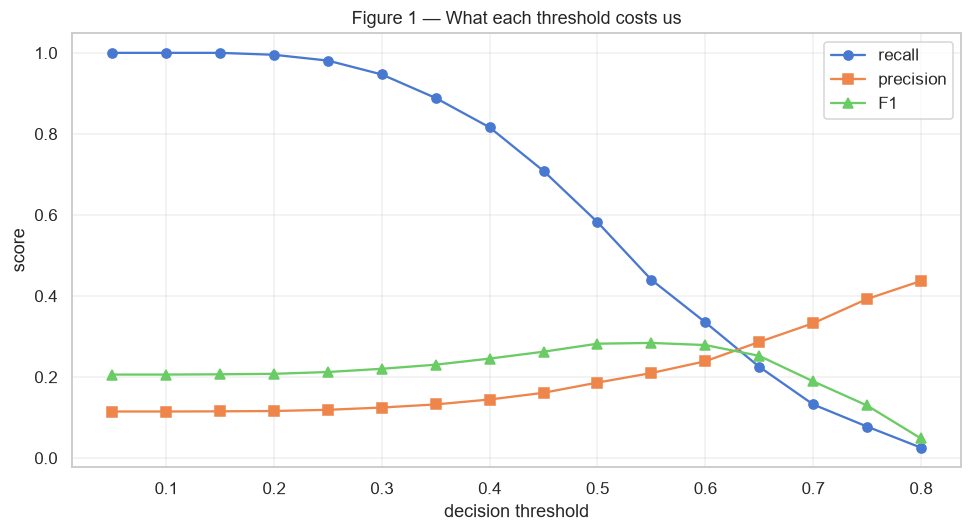

As the threshold rises, recall falls first: those are patients we stop
catching. Precision rises slowly because alerts become more selective.


In [12]:
# --- Chart 1: the trade-off curve ----------------------------------------------
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thr_table["threshold"], thr_table["recall"], marker="o", label="recall")
ax.plot(thr_table["threshold"], thr_table["precision"], marker="s", label="precision")
ax.plot(thr_table["threshold"], thr_table["f1"], marker="^", label="F1")
ax.set_xlabel("decision threshold")
ax.set_ylabel("score")
ax.set_title("Figure 1 — What each threshold costs us")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("As the threshold rises, recall falls first: those are patients we stop")
print("catching. Precision rises slowly because alerts become more selective.")

In [13]:
# --- Two candidate policies, chosen out loud -----------------------------------
TARGET_RECALL = 0.75

# (1) F1-optimal: best balance of precision and recall on the test set
f1_row = thr_table.loc[thr_table["f1"].idxmax()]
CHOSEN = float(f1_row["threshold"])

# (2) recall-first: the HIGHEST threshold that still reaches the target recall
#     (sorting by recall ascending picks the most selective qualifying rule)
recall_rule = thr_table[thr_table["recall"] >= TARGET_RECALL].sort_values("recall")
recall_threshold = float(recall_rule.iloc[0]["threshold"])

print(f"deployed threshold (F1-optimal) : {CHOSEN:.2f}")
print(f"  recall {f1_row['recall']:.1%} | precision {f1_row['precision']:.1%} "
      f"| alerts {int(f1_row['alerts']):,} ({f1_row['alerts_per_100_stays']:.0f} per 100 stays)")
print()
print(f"recall-first alternative        : {recall_threshold:.2f}")
r_row = recall_rule.iloc[0]
print(f"  recall {r_row['recall']:.1%} | precision {r_row['precision']:.1%} "
      f"| alerts {int(r_row['alerts']):,} ({r_row['alerts_per_100_stays']:.0f} per 100 stays)")
print()
print("We ship the F1-optimal rule and report the other one: a rule that alerts")
print("two thirds of all discharges is not a usable workflow, even though it")
print("catches more patients. That trade belongs to the hospital, not the model.")

deployed threshold (F1-optimal) : 0.55
  recall 44.0% | precision 21.0% | alerts 4,834 (24 per 100 stays)

recall-first alternative        : 0.40
  recall 81.6% | precision 14.4% | alerts 13,022 (65 per 100 stays)

We ship the F1-optimal rule and report the other one: a rule that alerts
two thirds of all discharges is not a usable workflow, even though it
catches more patients. That trade belongs to the hospital, not the model.


In [14]:
final_pred = (tuned_proba >= CHOSEN).astype(int)
print("Test-set performance at the deployed threshold:")
print(f"  recall    : {recall_score(y_test, final_pred):.1%}"
      f"  -> of the real readmissions, we catch this share")
print(f"  precision : {precision_score(y_test, final_pred):.1%}"
      f"  -> of our alerts, this share really return")
print(f"  F1        : {f1_score(y_test, final_pred):.3f}")
print(f"  alerts    : {final_pred.sum():,} of {len(y_test):,} stays "
      f"({final_pred.mean():.1%})")

Test-set performance at the deployed threshold:
  recall    : 44.0%  -> of the real readmissions, we catch this share
  precision : 21.0%  -> of our alerts, this share really return
  F1        : 0.284
  alerts    : 4,834 of 20,075 stays (24.1%)


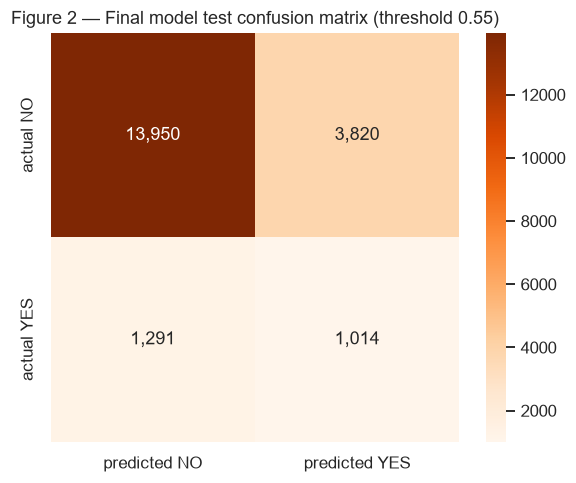

true negatives   13,950  correctly sent home without an alert
false positives   3,820  alerts for patients who did NOT return (cost: nurse time)
false negatives   1,291  readmissions we MISSED (cost: patient safety)
true positives    1,014  readmissions we caught


In [15]:
# --- Chart 2: final confusion matrix -------------------------------------------
cm = confusion_matrix(y_test, final_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Oranges", ax=ax, square=True,
            xticklabels=["predicted NO", "predicted YES"],
            yticklabels=["actual NO", "actual YES"])
ax.set_title(f"Figure 2 — Final model test confusion matrix (threshold {CHOSEN:.2f})")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"true negatives  {tn:>7,}  correctly sent home without an alert")
print(f"false positives {fp:>7,}  alerts for patients who did NOT return (cost: nurse time)")
print(f"false negatives {fn:>7,}  readmissions we MISSED (cost: patient safety)")
print(f"true positives  {tp:>7,}  readmissions we caught")


## 5. Explainability — which features drive the predictions?

A model the hospital cannot question is a model the hospital will not use. We use
**SHAP** (SHapley Additive exPlanations):

- Every prediction starts from a baseline (the average risk, ~11%).
- Each feature **pushes the risk up or down** from that baseline.
- SHAP fairly splits the credit among all features.

For a tree model the SHAP values are exact and fast. We explain a random sample
of 2,000 test stays, then look at single patients.


In [16]:
# stratified sample of test stays for explanation (fast + representative)
shap_idx = pd.concat([
    y_test[y_test == 1].sample(1000, random_state=RANDOM_STATE),
    y_test[y_test == 0].sample(1000, random_state=RANDOM_STATE),
]).index
X_shap = X_test.loc[shap_idx]

explainer = shap.TreeExplainer(final_gbm)
shap_values = explainer.shap_values(X_shap, check_additivity=False)
print("shap values shape:", np.asarray(shap_values).shape,
      "| features:", X_shap.shape[1])

shap values shape: (2000, 222) | features: 222



### 5.1 The overall picture — which features matter, and in which direction


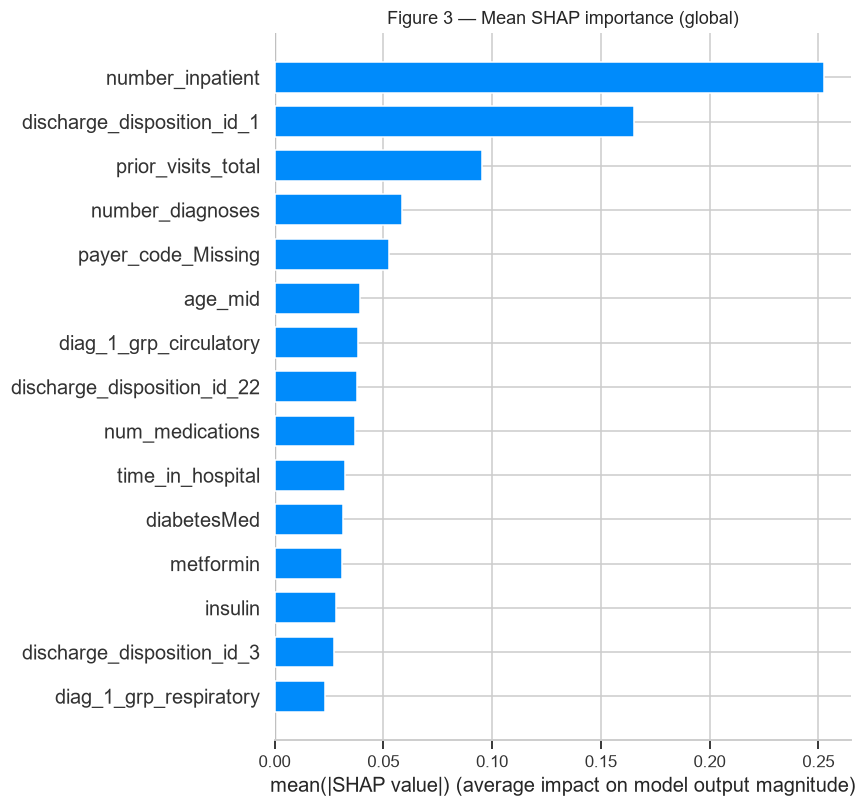

Read it as: on average, how much each feature moved the risk prediction.
Longer bar = more influence on the model's decisions.


In [17]:
# --- Chart 3: global importance ---------------------------------------------------
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False, max_display=15)
plt.title("Figure 3 — Mean SHAP importance (global)")
plt.tight_layout()
plt.show()

print("Read it as: on average, how much each feature moved the risk prediction.")
print("Longer bar = more influence on the model's decisions.")

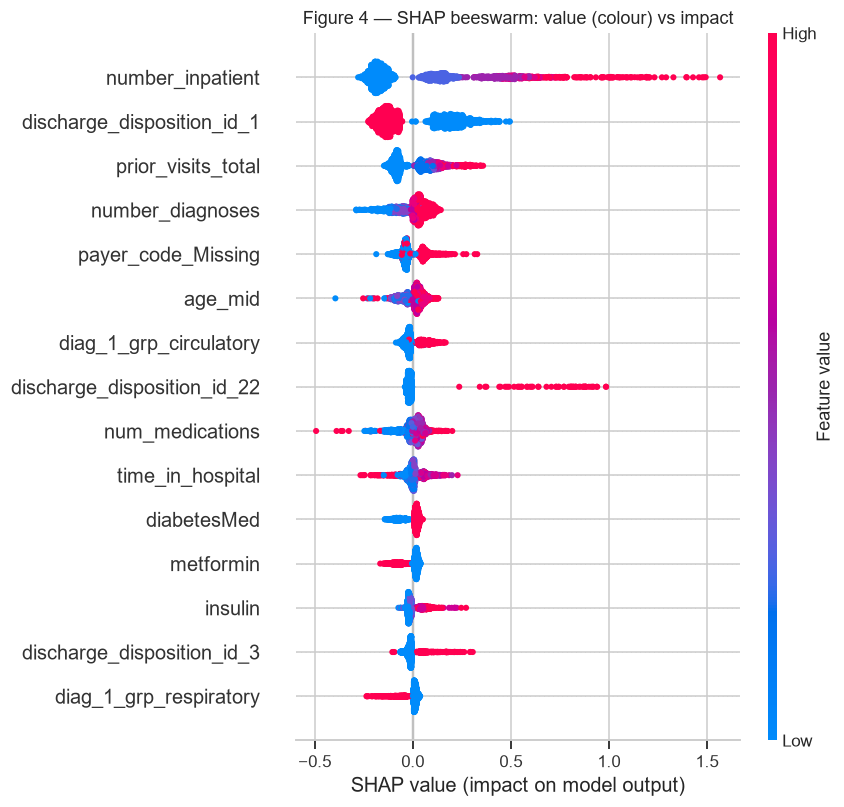

How to read it:
  each dot is ONE stay; x = how much that feature pushed the risk
  colour = the feature's value: red = high, blue = low
  e.g. if number_inpatient dots run red on the right, many prior stays
  push the risk UP -- which matches our Chapter 1 finding.


In [18]:
# --- Chart 4: direction and distribution ---------------------------------------
shap.summary_plot(shap_values, X_shap, show=False, max_display=15)
plt.title("Figure 4 — SHAP beeswarm: value (colour) vs impact")
plt.tight_layout()
plt.show()

print("How to read it:")
print("  each dot is ONE stay; x = how much that feature pushed the risk")
print("  colour = the feature's value: red = high, blue = low")
print("  e.g. if number_inpatient dots run red on the right, many prior stays")
print("  push the risk UP -- which matches our Chapter 1 finding.")


### 5.2 One patient at a time — the chart a nurse could be shown

A **waterfall** explains a single prediction: baseline → each feature's push →
final risk.


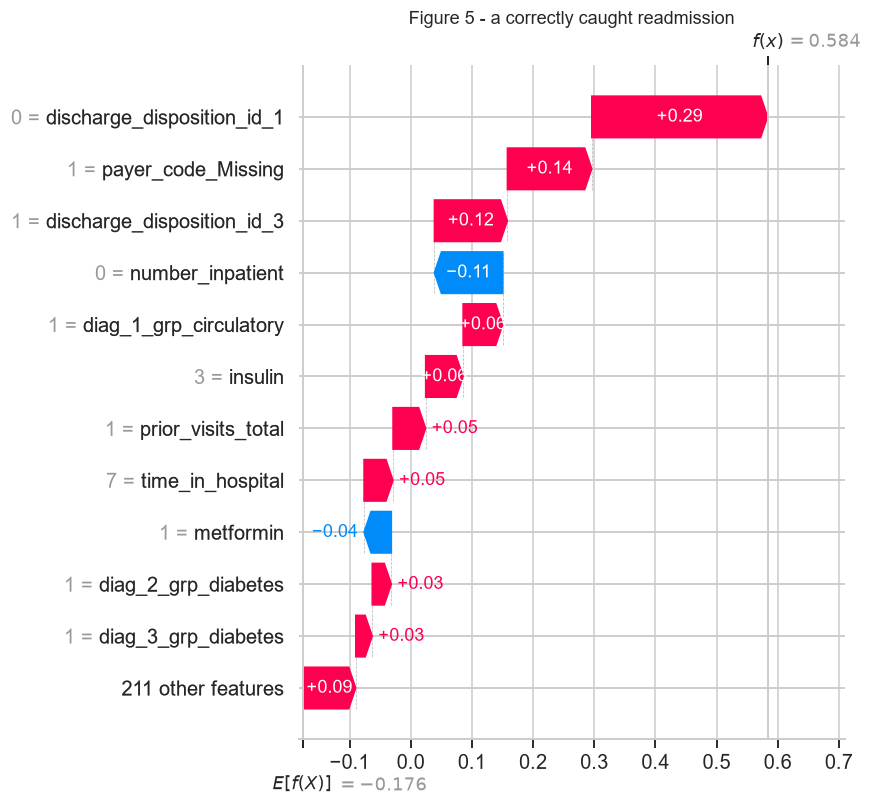

model risk for this stay: 64.2%  (threshold 0.55)
----------------------------------------------------------------------


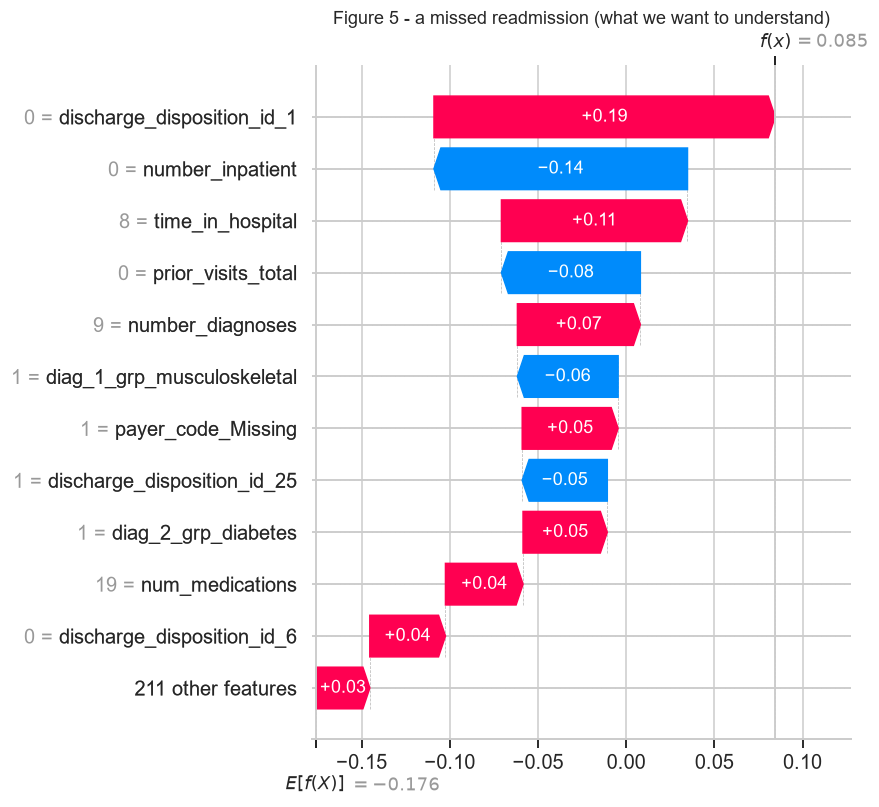

model risk for this stay: 52.1%  (threshold 0.55)
----------------------------------------------------------------------


In [19]:
# pick one true positive (a patient the model caught) and one false negative
pred_all = (tuned_proba >= CHOSEN).astype(int)
tp_idx = y_test.index[(y_test == 1) & (pred_all == 1)][0]
fn_idx = y_test.index[(y_test == 1) & (pred_all == 0)][0]

for label, idx in [("a correctly caught readmission", tp_idx),
                   ("a missed readmission (what we want to understand)", fn_idx)]:
    x_one = X_test.loc[[idx]]
    sv_one = explainer.shap_values(x_one, check_additivity=False)
    st = (shap.Explanation(values=np.asarray(sv_one)[0],
                           base_values=explainer.expected_value,
                           data=x_one.iloc[0], feature_names=list(X_test.columns)))
    fig = shap.plots.waterfall(st, max_display=12, show=False)
    if hasattr(fig, "set_size_inches"):     # shap returns different objects by version
        fig.set_size_inches(9, 6)
    plt.title(f"Figure 5 - {label}", fontsize=12)
    plt.tight_layout()
    plt.show()

    proba_one = final_gbm.predict_proba(x_one)[0, 1]
    print(f"model risk for this stay: {proba_one:.1%}  (threshold {CHOSEN:.2f})")
    print("-" * 70)


## 6. Fairness — does the model work equally well for everyone?

A model can be accurate overall and still fail one group. We break the test
results down by **race** and **gender** and compare recall: *"when a patient from
group X truly returned, how often did we alert?"*

This matters because Part 1 showed race/gender are barely predictive — but the
model could still perform worse on a minority group, and that is a fairness
failure even if the headline numbers look good.


In [20]:
# Reconstruct the demographic groups from the one-hot columns
race_cols = [c for c in X_test.columns if c.startswith("race_")]
def get_group(cols, prefix):
    sub = X_test[cols]
    labels = sub.idxmax(axis=1).str.replace(prefix, "", regex=False)
    labels[sub.sum(axis=1) == 0] = "unmapped"
    return labels

X_test["_race"] = get_group(race_cols, "race_")
X_test["_gender"] = np.where(X_test["gender"] == 0, "Female",
                             np.where(X_test["gender"] == 1, "Male", "Other"))

overall_recall = recall_score(y_test, final_pred)
print(f"overall recall: {overall_recall:.1%}")
print()
for group_col in ["_race", "_gender"]:
    stats = []
    for g, mask in X_test.groupby(group_col).groups.items():
        m = X_test.index.isin(mask)
        stats.append({
            "group": g,
            "stays": int(m.sum()),
            "readmit_rate": round(y_test[m].mean(), 3),
            "recall": round(recall_score(y_test[m], final_pred[m], zero_division=0), 3),
            "precision": round(precision_score(y_test[m], final_pred[m],
                                               zero_division=0), 3),
        })
    t = pd.DataFrame(stats).sort_values("stays", ascending=False)
    print(f"--- by {group_col.lstrip('_')} ---")
    print(t.to_string(index=False))
    print()

overall recall: 44.0%



--- by race ---
          group  stays  readmit_rate  recall  precision
      Caucasian  15011         0.119   0.440      0.215
AfricanAmerican   3814         0.109   0.475      0.204
        Missing    416         0.091   0.289      0.175
       Hispanic    387         0.078   0.333      0.122
          Other    313         0.096   0.200      0.102
          Asian    134         0.097   0.538      0.412

--- by gender ---
 group  stays  readmit_rate  recall  precision
Female  10657         0.111   0.444      0.197
  Male   9417         0.119   0.436      0.225
 Other      1         0.000   0.000      0.000



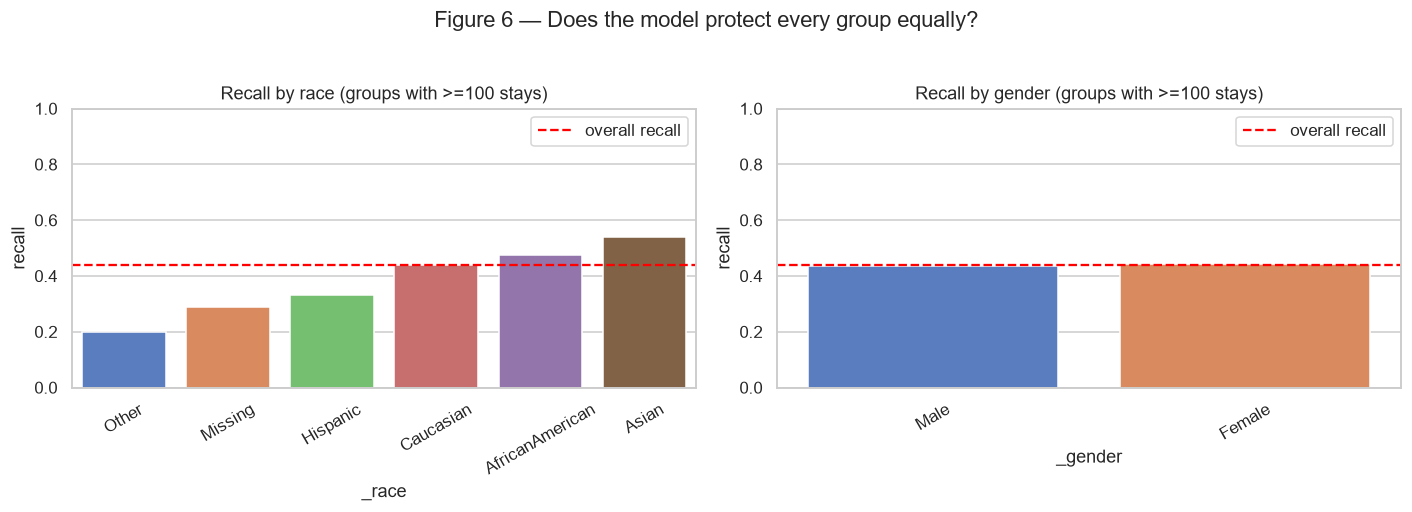

If a bar sits well below the red line, the model is less protective for
that group -- a fairness finding that must be reported, not averaged away.


In [21]:
# --- Chart 6: recall by group ---------------------------------------------------
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["_race", "_gender"]):
    t = (X_test.groupby(col)
             .apply(lambda d: pd.Series({
                 "stays": len(d),
                 "recall": recall_score(y_test.loc[d.index], final_pred[d.index],
                                        zero_division=0)}),
                    include_groups=False)
             .reset_index())
    t = t[t["stays"] >= 100]                     # groups big enough to judge
    t = t.sort_values("recall")
    sns.barplot(data=t, x=t.columns[0], y="recall", ax=ax, palette="muted")
    ax.axhline(overall_recall, color="red", ls="--", lw=1.5, label="overall recall")
    ax.set_ylim(0, 1)
    ax.set_title(f"Recall by {col.lstrip('_')} (groups with >=100 stays)")
    ax.tick_params(axis="x", rotation=30)
    ax.legend()
plt.suptitle("Figure 6 — Does the model protect every group equally?", y=1.03)
plt.tight_layout()
plt.show()

print("If a bar sits well below the red line, the model is less protective for")
print("that group -- a fairness finding that must be reported, not averaged away.")


## 7. Limitations and why this must not touch a real ward

1. **The data is from 1999–2008.** Readmission patterns, treatments and coding
   practices have changed. A model trained on it is a historical artefact.
2. **One payer, one provider network.** 130 hospitals of one insurer: not
   necessarily representative of another hospital, state or country.
3. **Labels are imperfect.** "NO" lumps together "fine" and "returned but we
   never saw it" — including people who died or moved away.
4. **No socio-economic data.** Housing, transport, income and social support
   drive readmission strongly and are absent — so the model cannot see the real
   causes, only their shadows.
5. **Splits are random, not temporal.** The honest test is "train on 1999–2004,
   test on 2005–2008"; a random split is the easier version.
6. **Calibration is not guaranteed.** A 30% output does not automatically mean
   "30 out of 100 such patients return"; calibration must be verified per site.
7. **No clinical trial.** Lacking prospective validation, the model has zero
   evidence that acting on it helps patients — it may even cause harm by
   misdirecting scarce follow-up resources.

**Therefore:** this is a portfolio project demonstrating an honest ML pipeline,
not a clinical device.


In [22]:
# --- Save everything the report and the app need --------------------------------
MODELS = PROC.parent.parent / "models"
joblib.dump(final_gbm, MODELS / "final_model.joblib")

summary = {
    "model": "LightGBM (tuned on full training set)",
    "chosen_threshold": CHOSEN,
    "test_roc_auc": round(roc_auc_score(y_test, tuned_proba), 4),
    "test_pr_auc": round(average_precision_score(y_test, tuned_proba), 4),
    "test_recall": round(recall_score(y_test, final_pred), 4),
    "test_precision": round(precision_score(y_test, final_pred), 4),
    "test_f1": round(f1_score(y_test, final_pred), 4),
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
}
with open(PROC / "final_model_summary.json", "w") as f:
    json.dump(summary, f, indent=1)

print(json.dumps(summary, indent=1))
print("saved models/final_model.joblib and data/processed/final_model_summary.json")

{
 "model": "LightGBM (tuned on full training set)",
 "chosen_threshold": 0.55,
 "test_roc_auc": 0.6687,
 "test_pr_auc": 0.226,
 "test_recall": 0.4399,
 "test_precision": 0.2098,
 "test_f1": 0.2841,
 "confusion_matrix": {
  "tn": 13950,
  "fp": 3820,
  "fn": 1291,
  "tp": 1014
 }
}
saved models/final_model.joblib and data/processed/final_model_summary.json



---
**End of notebook 03.** All parts of the brief are now covered:
Part 1 → notebook 01 · Part 2 → notebook 02 §2–6 · Part 3 → notebooks 02–03 ·
Part 4 → notebook 03 §5–7 · Part 5 → `app/app.py` · Part 6 → `report.md`.
